仮説2（フィッシャー情報量の消失）の実証シミュレーションを開始します... (各水準 2000回並列試行)
確信度 Beta = 0.10 の計算中...
確信度 Beta = 0.14 の計算中...
確信度 Beta = 0.18 の計算中...
確信度 Beta = 0.25 の計算中...
確信度 Beta = 0.34 の計算中...
確信度 Beta = 0.45 の計算中...
確信度 Beta = 0.62 の計算中...
確信度 Beta = 0.83 の計算中...
確信度 Beta = 1.13 の計算中...
確信度 Beta = 1.53 の計算中...
確信度 Beta = 2.07 の計算中...
確信度 Beta = 2.80 の計算中...
確信度 Beta = 3.79 の計算中...
確信度 Beta = 5.13 の計算中...
確信度 Beta = 6.95 の計算中...
確信度 Beta = 9.41 の計算中...
確信度 Beta = 12.74 の計算中...
確信度 Beta = 17.25 の計算中...
確信度 Beta = 23.36 の計算中...
確信度 Beta = 31.62 の計算中...


,Beta,Mean_Fisher_Info,Mean_Sum_P_Sq,Collapse_Rate,Collapse_MCSE,CI_Lower,CI_Upper
0,0.100000,0.008000,0.200039,1.0,0.0,1.0,1.0
1,0.135388,0.014663,0.200072,1.0,0.0,1.0,1.0
2,0.183298,0.026874,0.200134,1.0,0.0,1.0,1.0
3,0.248163,0.049253,0.200244,1.0,0.0,1.0,1.0
4,0.335982,0.090256,0.200453,0.0,0.0,0.0,0.0


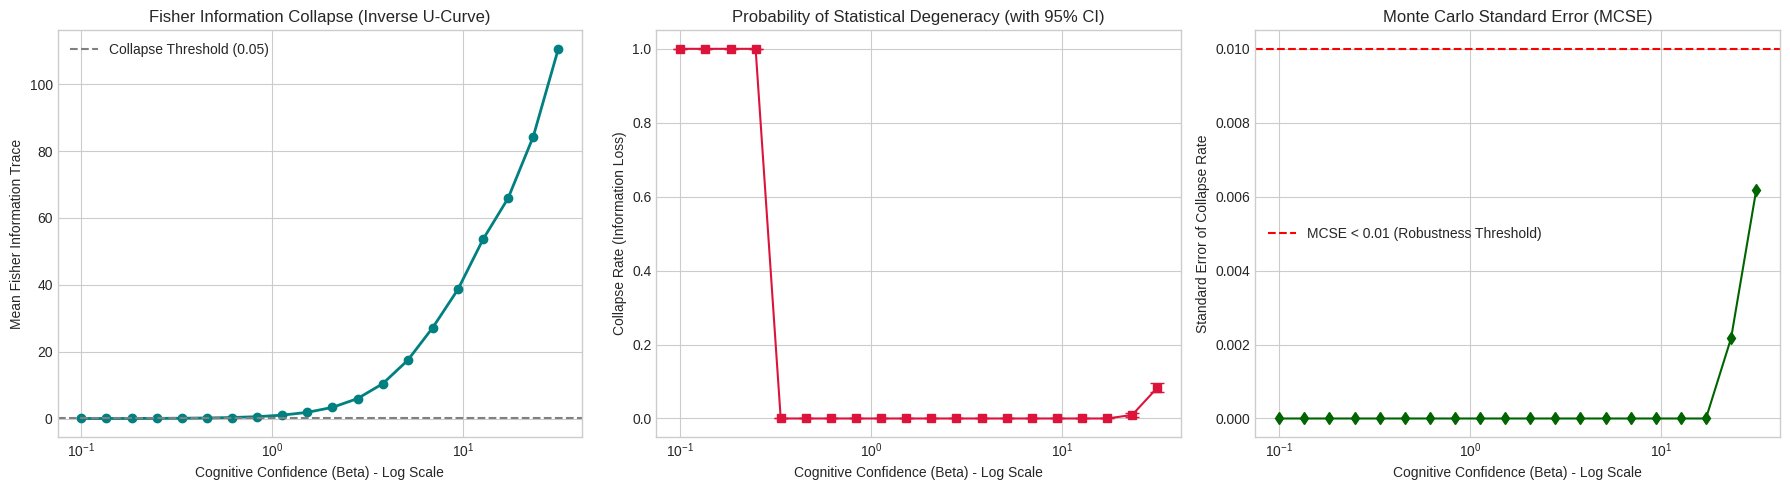


検証完了。結果を圧縮しました: hypothesis2_fisher_collapse.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from joblib import Parallel, delayed
from google.colab import files

warnings.filterwarnings("ignore")

# ==========================================
# 1. 実証的キャリブレーションと検証設定
# ==========================================
# ColabのCPUをフル活用するための並列試行回数 (十分性はMCSEで証明)
N_TRIALS = 2000
# 認知バイアス（確信度 beta）の対数スケール変動幅（0.1 から 30 まで）
beta_values = np.logspace(-1, 1.5, num=20)
# 情報消失とみなすフィッシャー情報量の閾値
FI_THRESHOLD = 0.05

output_dir = "hypothesis2_fisher_collapse"
os.makedirs(output_dir, exist_ok=True)

print(f"仮説2（フィッシャー情報量の消失）の実証シミュレーションを開始します... (各水準 {N_TRIALS}回並列試行)")

# ==========================================
# 2. 並列実行用の単一試行関数 (初期値依存の完全排除)
# ==========================================
def simulate_h2_single_trial(beta):
    # 選択肢の数 (5件法)
    K = 5

    # 1. ターゲット選択肢の一様ランダム生成 T1, T2, T3 ~ U(1, 5)
    T = np.random.randint(1, K + 1, size=3)

    # 2. 潜在ウェイトの一様生成 (ディリクレ分布から生成し、総和=1を保証)
    v = np.random.dirichlet(np.ones(3))

    # 3. 距離減衰パラメータのランダム化 alpha ~ U(0.8, 1.2)
    alpha = np.random.uniform(0.8, 1.2, size=3)

    # 4. AHP距離減衰モデルによる論理的重み w の計算
    u = np.zeros((3, K))
    for m in range(3):
        distances = np.abs(np.arange(1, K + 1) - T[m])
        exp_decay = np.exp(-alpha[m] * distances)
        u[m, :] = exp_decay / np.sum(exp_decay)

    w = np.dot(v, u) # (K,)

    # 5. Softmax関数による確率ベクトル p の生成
    # betaは外部から与えられる認知確信度
    exp_w = np.exp(beta * w)
    p = exp_w / np.sum(exp_w)

    # 6. フィッシャー情報量（FI）のスカラー評価値（Trace）の算出
    # 多項ロジットモデルのFisher Information行列のTraceに比例する指標
    sum_p_sq = np.sum(p ** 2)
    fi_trace = (beta ** 2) * (1.0 - sum_p_sq)

    # FIが閾値を下回った場合、推定に必要な情報が喪失した(Degeneracy)と判定
    is_collapsed = 1 if fi_trace < FI_THRESHOLD else 0

    return [fi_trace, is_collapsed, sum_p_sq]

# ==========================================
# 3. メインループ (Joblibによる並列処理)
# ==========================================
results_summary = []

for beta in beta_values:
    print(f"確信度 Beta = {beta:.2f} の計算中...")

    # 並列処理の実行
    trial_results = Parallel(n_jobs=-1)(
        delayed(simulate_h2_single_trial)(beta) for _ in range(N_TRIALS)
    )
    trial_results = np.array(trial_results)

    # 結果の抽出
    mean_fi_trace = np.mean(trial_results[:, 0])
    collapse_count = np.sum(trial_results[:, 1])
    mean_sum_p_sq = np.mean(trial_results[:, 2])

    # キャリブレーション指標: 縮退率と MCSE の計算
    collapse_rate = collapse_count / N_TRIALS
    mcse_collapse = np.sqrt((collapse_rate * (1 - collapse_rate)) / N_TRIALS)

    results_summary.append({
        "Beta": beta,
        "Mean_Fisher_Info": mean_fi_trace,
        "Mean_Sum_P_Sq": mean_sum_p_sq, # 完全分離(1.0への接近)の監視
        "Collapse_Rate": collapse_rate,
        "Collapse_MCSE": mcse_collapse,
        "CI_Lower": max(0, collapse_rate - 1.96 * mcse_collapse),
        "CI_Upper": min(1, collapse_rate + 1.96 * mcse_collapse)
    })

df_res = pd.DataFrame(results_summary)
df_res.to_csv(f"{output_dir}/fisher_information_collapse.csv", index=False)
display(df_res.head())

# ==========================================
# 4. 評価の可視化
# ==========================================
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# グラフ1: 確信度 Beta に対するフィッシャー情報量の非線形変化 (逆U字カーブ)
axes[0].plot(df_res["Beta"], df_res["Mean_Fisher_Info"], marker='o', color='teal', linewidth=2)
axes[0].axhline(y=FI_THRESHOLD, color='gray', linestyle='--', label=f'Collapse Threshold ({FI_THRESHOLD})')
axes[0].set_xscale('log')
axes[0].set_title("Fisher Information Collapse (Inverse U-Curve)")
axes[0].set_xlabel("Cognitive Confidence (Beta) - Log Scale")
axes[0].set_ylabel("Mean Fisher Information Trace")
axes[0].legend()

# グラフ2: 情報喪失率 (Degeneracy Rate) と 95%信頼区間
axes[1].errorbar(df_res["Beta"], df_res["Collapse_Rate"],
                 yerr=1.96 * df_res["Collapse_MCSE"], fmt='-s', color='crimson', capsize=5)
axes[1].set_xscale('log')
axes[1].set_title("Probability of Statistical Degeneracy (with 95% CI)")
axes[1].set_xlabel("Cognitive Confidence (Beta) - Log Scale")
axes[1].set_ylabel("Collapse Rate (Information Loss)")

# グラフ3: MCSEによる試行回数の十分性証明
axes[2].plot(df_res["Beta"], df_res["Collapse_MCSE"], marker='d', color='darkgreen')
axes[2].axhline(y=0.01, color='red', linestyle='--', label='MCSE < 0.01 (Robustness Threshold)')
axes[2].set_xscale('log')
axes[2].set_title("Monte Carlo Standard Error (MCSE)")
axes[2].set_xlabel("Cognitive Confidence (Beta) - Log Scale")
axes[2].set_ylabel("Standard Error of Collapse Rate")
axes[2].legend()

plt.tight_layout()
plt.savefig(f"{output_dir}/h2_fisher_collapse_plots.png", dpi=300)
plt.show()

# ==========================================
# 5. ZIP化とダウンロード
# ==========================================
zip_filename = "hypothesis2_fisher_collapse.zip"
with zipfile.ZipFile(zip_filename, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files_list in os.walk(output_dir):
        for file in files_list:
            file_path = os.path.join(root, file)
            zipf.write(file_path, arcname=file)

print(f"\n検証完了。結果を圧縮しました: {zip_filename}")
files.download(zip_filename)